# Support Vector Machines
SVM претставува модел на учење со надзор кој воглавно се применува за класификација, но истиот пренаменет модел наоѓа примена и во областа на регресија. Една од главните карактеристики на овој модел е неговата робустност при предвидување. Поради тоа тој уште се нарекува класификатор кој наоѓа граница на предвидување со максимално растојание од точките на податочното множество. Како таков може да се карактеризира со следните предности и недостатоци:

|Предности|Недостатоци|
|---|---|
|Може да предвидува добро на широк опсег на податочни множества|Времето на тренирање и искористувањето на меморија се зголемува со зголемување на податочното множество|    
|Сестраност: нуди можност за искористување на јадра со цел за нелинеарно предвидување| Бара внимателно нагодување на параметрите за тренирање|
|Предвидува добро за податочни множества со голем и мал број на карактеристики| Тешко е да се утврди како било направено предвидувањето (проблем на црна кутија)|
||Моделот кажува само дали припаѓа на една класа, но не и со колкава веројатност е сигурен дека припаѓа на истата. Ова може да се надмине со помош дополнителни алатки(Platt Scaling)|

Еден од клучните аспекти при тренирање на еден SVM модел е нагодување на неговите параметри за тренирање. Еден од највлијателните параметри се:

* **C:** Параметар на регуларизација. При тоа $\lambda = \frac{1}{C}$. За регуларизација се користи l2 норма. Опсег на вредности: **[0, inf]**
* **gamma**: Коефициент на јадрото(kernel). Во случајот на гаусово јадро, овој параметер ја одредува широчината на ѕвоното. Множество на вредности: **[0, inf]**
* **kernel**: Тип на јадро кое ќе го користи алгоритмот. Јадрото се применува со цел да се овозможи предвидување на нелинеарни зависности. Тоа се реализира преку линеарна раздвојливост на податочното множество. Целта е да се преслика секоја од точка од податочното множество во повеќе димензионален простор каде што ќе се овозможи линеарна раздвојливост на множеството. Множество на вредности: **[‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’, ‘precomputed’]**
* **degree**: Во случај на полиномно јадро ('poly') го дефинира степенот на полиномот во случаи кога се користи полиномно јадро.

## Концепт на јадро (kernel)
Во следниот прилог ќе прикажеме едноставен пример за примена на полиномно јадро од втор ред со цел да се овозможи линеарна раздвојливост и при тоа да се разбере концептот на јадро.

1. Со помош на униформна распределба дефинираме: 10 точки во опсег [0, 10], 5 точки во опсег [0.5, 5], 10 точки во опсег [1.5, 10]
2. Секоја од групите на точки во трите опсези им доделуваме по класа на припадност
3. Го исцртуваме податочното множество

(-0.1, 0.5)

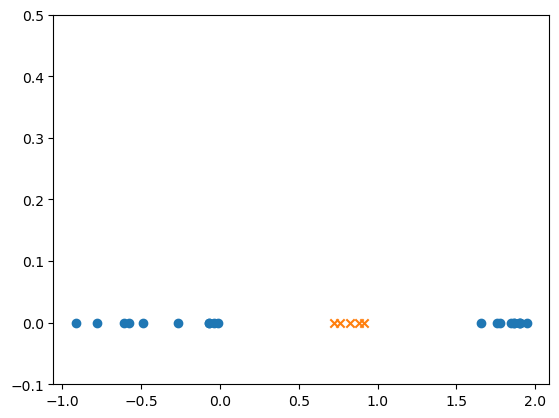

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.hstack((np.random.uniform(-1, 0, 10), np.random.uniform(0.5, 1, 5), np.random.uniform(1.5, 2, 10)))
y = np.hstack((np.ones((10, )), np.zeros((5, )), np.ones((10, ))))

plt.scatter(X[y == 1], np.zeros((20,)), marker='o')
plt.scatter(X[y == 0], np.zeros((5,)), marker='x')
plt.ylim([-1e-1, 0.5])

Од цртежот е очигледно дека не би можеле да го раздвоиме податочното множество со помош на една линија. За таа цел множество се пресликува во дводимензионален простор каде ново додадената димензија ќе биде $X^2$. На овој начин се применување всушност полиномно јадро.

1. Додаваме уште една карактеристика која ќе биде квадратот на првата карактеристика
2. Го исцртуваме новото податочно множество со новата карактеристика
3. Исцртуваме линија на предвидување која ќе ја раздвои едната од другата класа

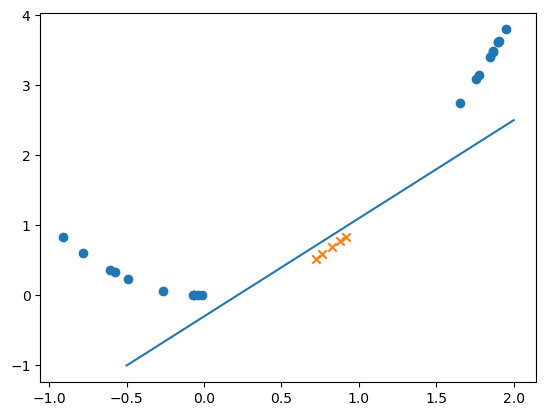

In [2]:
plt.scatter(X[y == 1], X[y == 1]**2, marker='o')
plt.scatter(X[y == 0], X[y == 0]**2, marker='x')
plt.plot(np.linspace(-0.5, 2, 20), 1.4*np.linspace(-0.5, 2, 20) - 0.3)

Со новата трансформација успеавме да ги раздвоиеме точките со помош на обична линија. На овој начин со примена на полиномно јадро му се дава моќ на моделот да прави нелинеарни предвидувања. Овој пристап исто така може да се применува и во логистичка регресија, но треба да се земе предвид дека поради природата на моделот, пресликувањата на податочното множество може да се направат пресметковно поевтино кај SVM во споредба со логистичка регресија или други модели.

## Параметри кај SVM модел
Изборот на параметрите на SVM може да се сумира со помош на следната табела:

| |Многу висока вредност|Многу ниска вредност|
|---|---|---|
|**C**|Висока варијанса(overfitting)|Висока пристрасност(underfitting)|
|**gamma('rbf')**|Висока варијанса(overfitting)|Висока пристрасност(underfitting)|
|**degree('poly')**|Висока варијанса(overfitting)|Висока пристрасност(underfitting)|

Понатамошно ќе покажаме визуелно што значи underfitting и overfitting од аспект на овие параметри.
## Параметар: Јадро(Kernel)
1. Земаме податочно множество кое има две карактеристика и 3 класи на предвидување
2. Тренираме модел на SVM за три различни јадра: линеарно ('linear'), гаусово ('rbf') и полиномно ('poly'). Се земаат default параметри за секој од моделите.
3. Ги исцртување зоните на предвидување за секој од трите модели

In [3]:
from sklearn import svm, datasets


iris = datasets.load_iris()
X = iris.data[:, :2] # земаме само две карактеристики со цел за визуелизација
y = iris.target

In [4]:
def plotSVC(title):
    x_min, x_max = X[:, 0].min() - 10, X[:, 0].max() + 10
    y_min, y_max = X[:, 1].min() - 10, X[:, 1].max() + 10
    h = np.abs((x_max / x_min)/100)
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h))
    plt.subplot(1, 1, 1)
    Z = svc.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired)
    plt.xlabel('Sepal length')
    plt.ylabel('Sepal width')
    plt.xlim(xx.min(), xx.max())
    plt.title(title)
    plt.show()

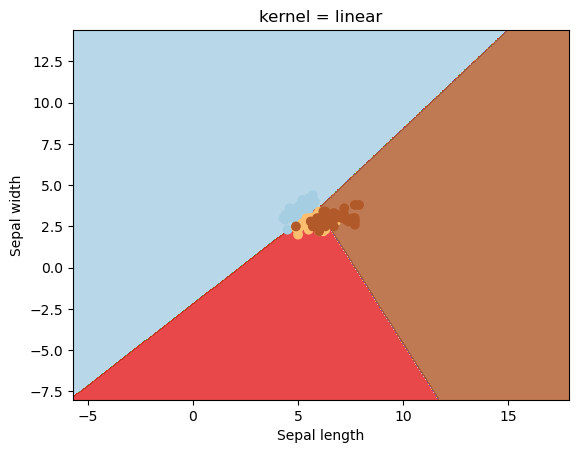

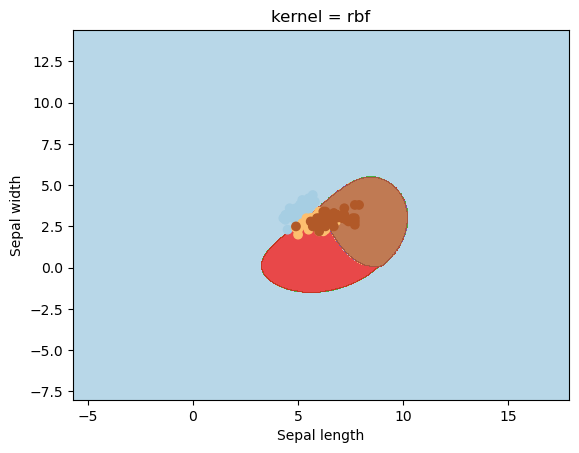

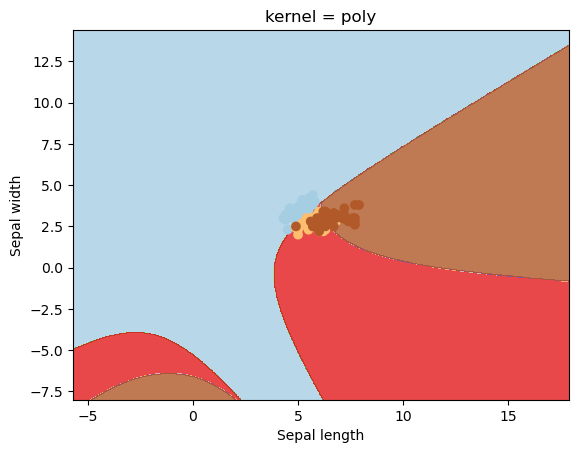

In [5]:
kernels = ['linear', 'rbf', 'poly']

for kernel in kernels:
    svc = svm.SVC(kernel=kernel).fit(X, y)
    plotSVC(f'kernel = {kernel}')

Според резултатите можеме да утврдиме дека јадрото ја утврдува математичката функција која се користи за раздвојување при класификација. Линеарно јадро подразбира класификација со помош на линеарна права, полиномно јадро подразбира класификација со помош на полином од ред 'degree', а гаусово јадро подразбира класификација со помош на на гаусова функција.
Од горе прикажаните графици може да се утврди следното:

* **Линеарно јадро** овзможува робустна класификација на податочни множества чии карактеристики овозможуваат линеарна класификација. Моделот се тренира мошне брзо кога се користи линеарно јадро. Дополнително може да се воочи дека овој тип на јадро овозможува моделот да екстраполира во случаи кога треба да ја предвиди класата на точка од податочното множество која што се наоѓа далеку од множеството за тренирање. За жал ова јадро потфрлува кога се во прашање покомплексни податочни множества
* **Гаусово јадро** овозможува нелинеарна класификација и се карактеризира со голема флексибилност. Функцијата на предвидување може да заземе различни форми во зависност од податочното множество. Според тоа ова јадро е мошне корисно кога се работи за комплексни податочни множества. Сепак мора да се земе предвид дека ова јадро има дополнителен параметар за нагодување(**gamma**), а тоа дополнително го отежнува процесот на тренирање. За разлика од линеарното јадро, од графикот може да се воочи дека гаусовото јадро потфрлува при екстраполација. Конкретно може да се воочи дека целиот простор надвор од множеството за тренирање го класифицра со припадност на само една класа (класата со сина боја). Поради нелинеарноста на јадрото овој модел побарува повеќе хардверски ресурси при тренирање. Несоодветно нагодување на параметрите кај ова јадро може многу лесно да доведе до модели со висока варијанса(overfitting). 
* **Полиномно јадро** овозможува линеарна и нелинеарна класификација каде што комплексноста на функцијата на предвидување зависи од редот на полиномот(**degree**). За разлика од гаусовото јадро, иако овозможува нелинеарна класификација сепак не се карактеризира со истата флексибилност. Со цел да овозможи добро предвидување треба да се одбере соодветниот ред на полиномот. Ова јадро може да се справува со проблемот на екстраполација, но не секогаш(погледнете ги зоните на предвидување во опсегот(-5.5, -7.7) до (2, -5)) по x оска. Потребните хардверски ресурси при тренирање зависат од редот на полиномот. Исто како гаусовото јадро и ова јадро исто така има дополнителен параметар за нагодување(**degree**) кој дополнително го отежнува процесот на тренирање.
## Параметар: gamma кaj гаусово јадро

1. На истото податочно множество од погоре тренираме SVM модел со гаусово јадро за различни вредности на параметарот gamma
2. Ги визуелизираме зоните на предвидување за различни вредности на параметарот gamma

In [6]:
def plotSVC(title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    h = np.abs((x_max / x_min)/100)
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h))
    plt.subplot(1, 1, 1)
    Z = svc.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired)
    plt.xlabel('Sepal length')
    plt.ylabel('Sepal width')
    plt.xlim(xx.min(), xx.max())
    plt.title(title)
    plt.show()

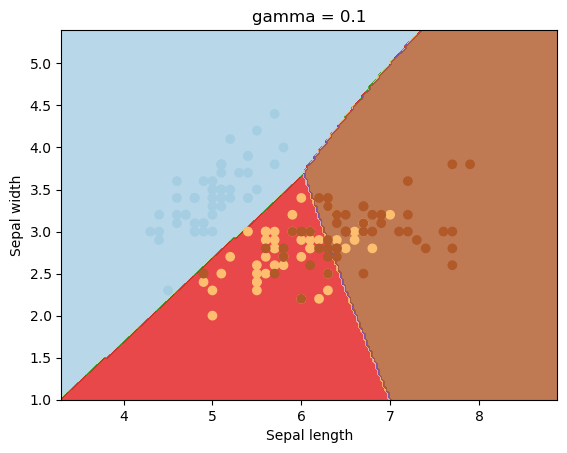

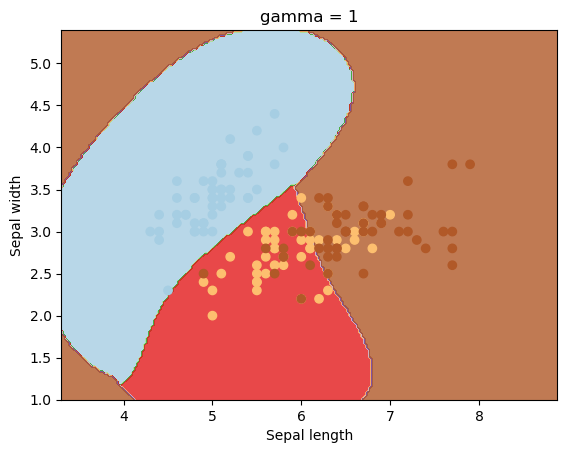

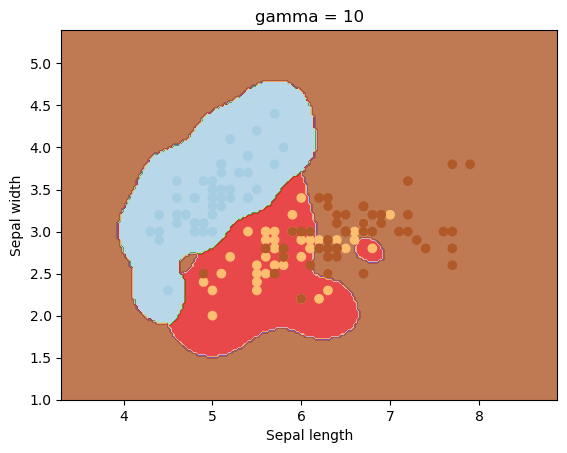

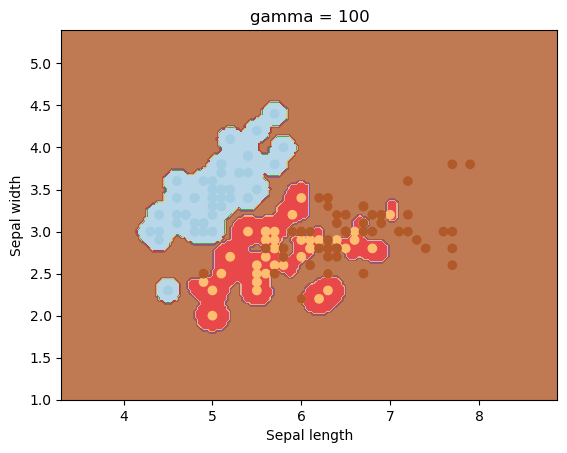

In [7]:
gammas = [0.1, 1, 10, 100]
for gamma in gammas:
    svc = svm.SVC(kernel='rbf', gamma=gamma).fit(X, y)
    plotSVC(f'gamma = {gamma}')

Од графиците може да се забележи дека варијансата на моделот се зголемува пропорционално со gamma параметарот. За високи вредности на gamma, моделот тежнее да се фокусира за точно предвидување на што е можно повеќе податоци, така што ќе изгради повеќе "базени" околу податочните точки. За големи вредности на gamma моделот тежнее да постигне совршено предвидување на множеството за тренирање така што ја влошува неговата ефикасност на предвидување кај нови податоци (проблем на overfitting). Графикот за $gamma=100$ е карактеристичен пример за overfitting на еден модел.
## Параметар: degree кај полиномно јадро

1. За истото податочно множество од погоре тренираме SVM модел за линеарно
2. Ги визуелизираме зоните на предвидување за различни вредности на параметарот degree

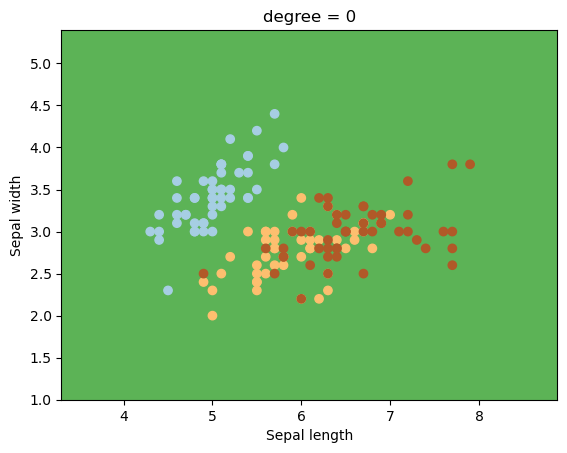

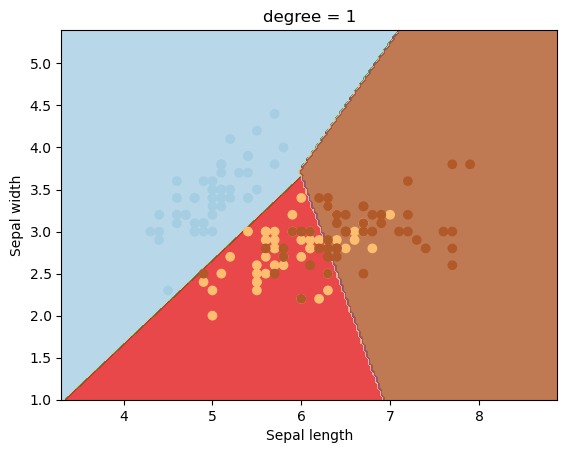

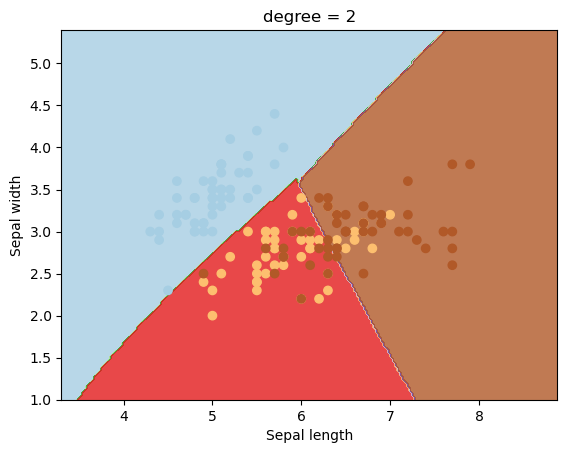

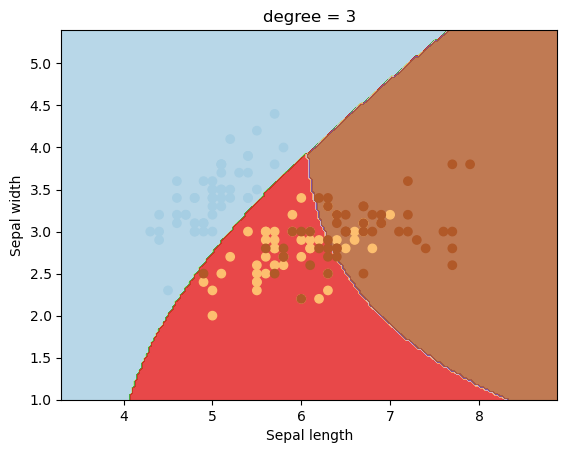

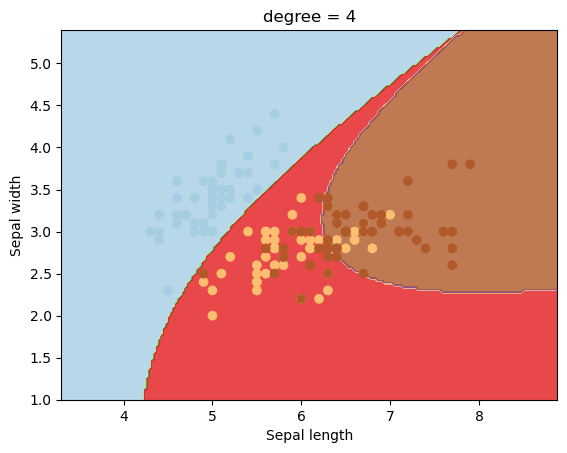

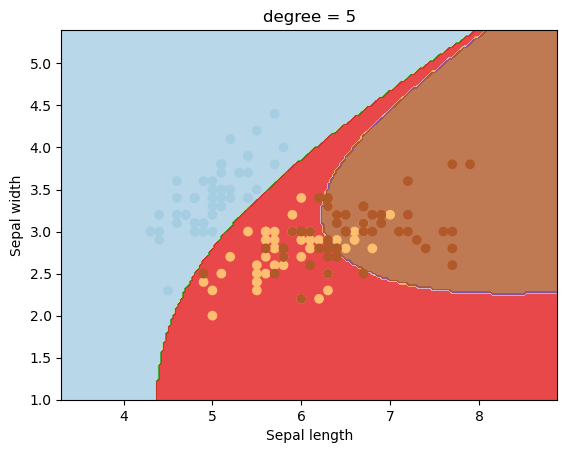

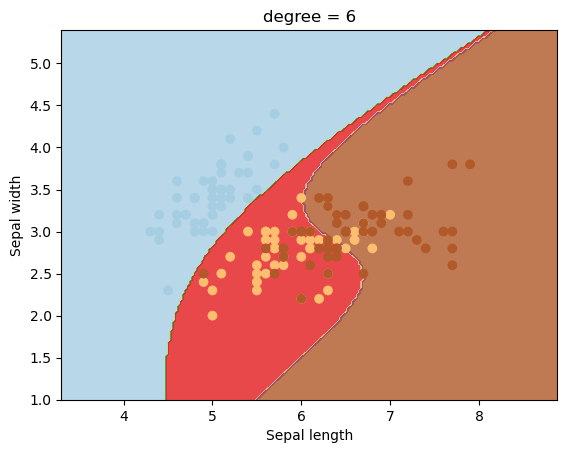

In [8]:
degrees = [0, 1, 2, 3, 4, 5, 6]
for degree in degrees:
    svc = svm.SVC(kernel='poly', degree=degree).fit(X, y)
    plotSVC(f'degree = {degree}')

Параметарот degree го дефинира редот на полиномот со чија помош се предвидува. Очигледно е дека полином од прв ред е исто како и линеарно јадро. Колку е поголем редот на полиномот, толку повеќе се зголемува и варијансата на моделот но сепак варијансата на моделот во овој случај дополнително зависи и од **C** параметарот. Возможно е моделот да има висок ред на полином, но сепак тој да има висока пристрасност(underfitting) доколку параметарот C е премногу низок, односно параметарот на регуларизација $\lambda$ е премногу висок
## Параметар: C
1. За истото податочно множество од погоре тренираме SVM модел за гаусово јадро со различни вредности на параметарот C
2. Ги визуелизираме зоните на предвидување за различни вредности на параметарот C

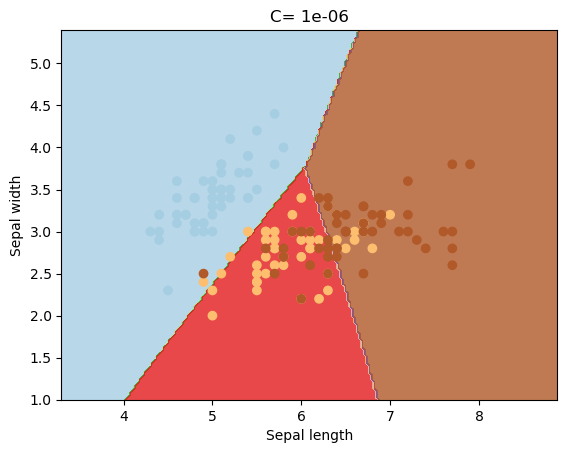

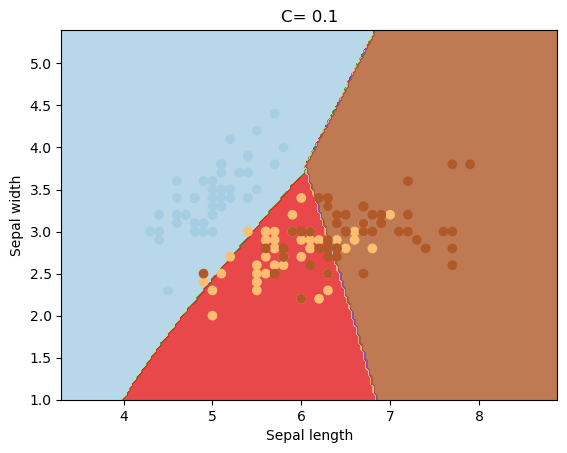

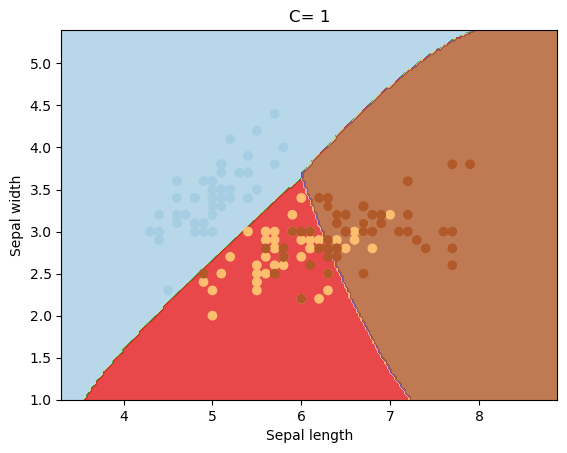

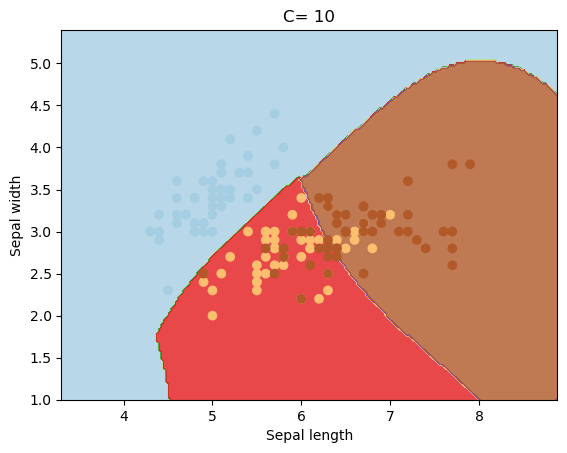

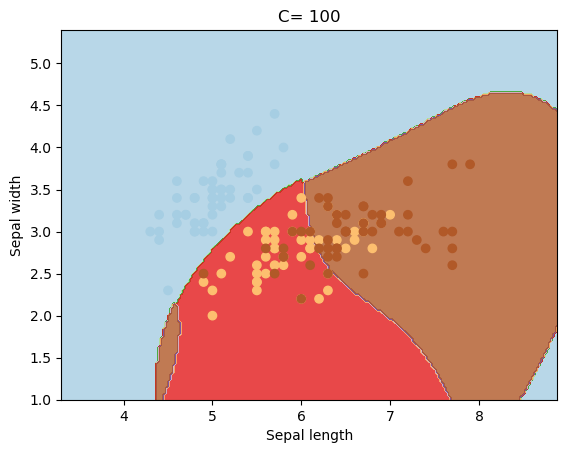

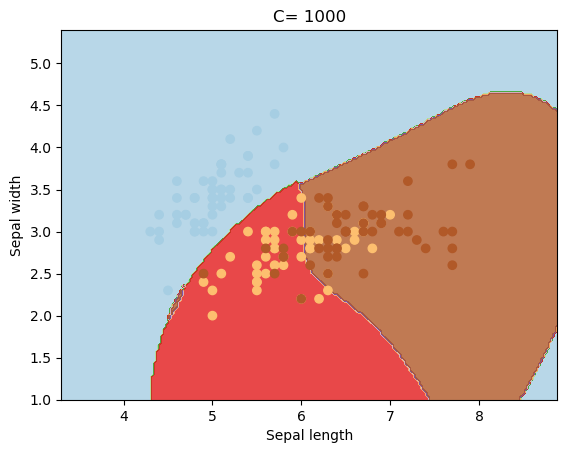

In [9]:
cs = [1e-6, 0.1, 1, 10, 100, 1000]
for c in cs:
   svc = svm.SVC(kernel='rbf', C=c).fit(X, y)
   plotSVC(f'C= {c}')

Параметарот C ја претставува вредноста со која го казнуваме моделот доколку направи грешка при негово тренирање. Со негова помош се управува компромисот помеѓу совршено предвидување на множеството за тренирање, кое може да доведе до overfitting, и глатка функција на предвидување која во некои случаи доведува до underfitting.
# Тренирање на SVM модел на Ирис податочното множество
„Ирис“ податочното множество содржи информации за 150 цвеќиња од 3 различни видови.

Трите различни видови се следни:

    Iris-setosa (бр. примероци = 50)
    Iris-versicolor (бр. примероци = 50)
    Iris-virginica (бр. примероци = 50)

Четирите карактеристикi од множеството се следни:

    sepal length in cm
    sepal width in cm
    petal length in cm
    petal width in cm
Тие се однесуваат на должината и ширината на листовите од стеблото и листовите од цветот. Во прилог се прикажани на сликата како изгледаат секој од трите вида на цвеќе.

## Iris Setosa

## Iris Versicolor

In [ ]:
url = 'http://upload.wikimedia.org/wikipedia/commons/9/9f/Iris_virginica.jpg'
Image(url,width=300, height=300)

## Потребни библиотеки и вчитување на податоци

In [13]:
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV

In [14]:
iris = sns.load_dataset('iris')
iris

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


# Истражување и визуелизација на податоци
### Прикажете ги на графици податочните точки за секој пар на карактеристики, доделувајќи им различна боја за секоја класа

**помош: seabron.pairplot(hue=?)**

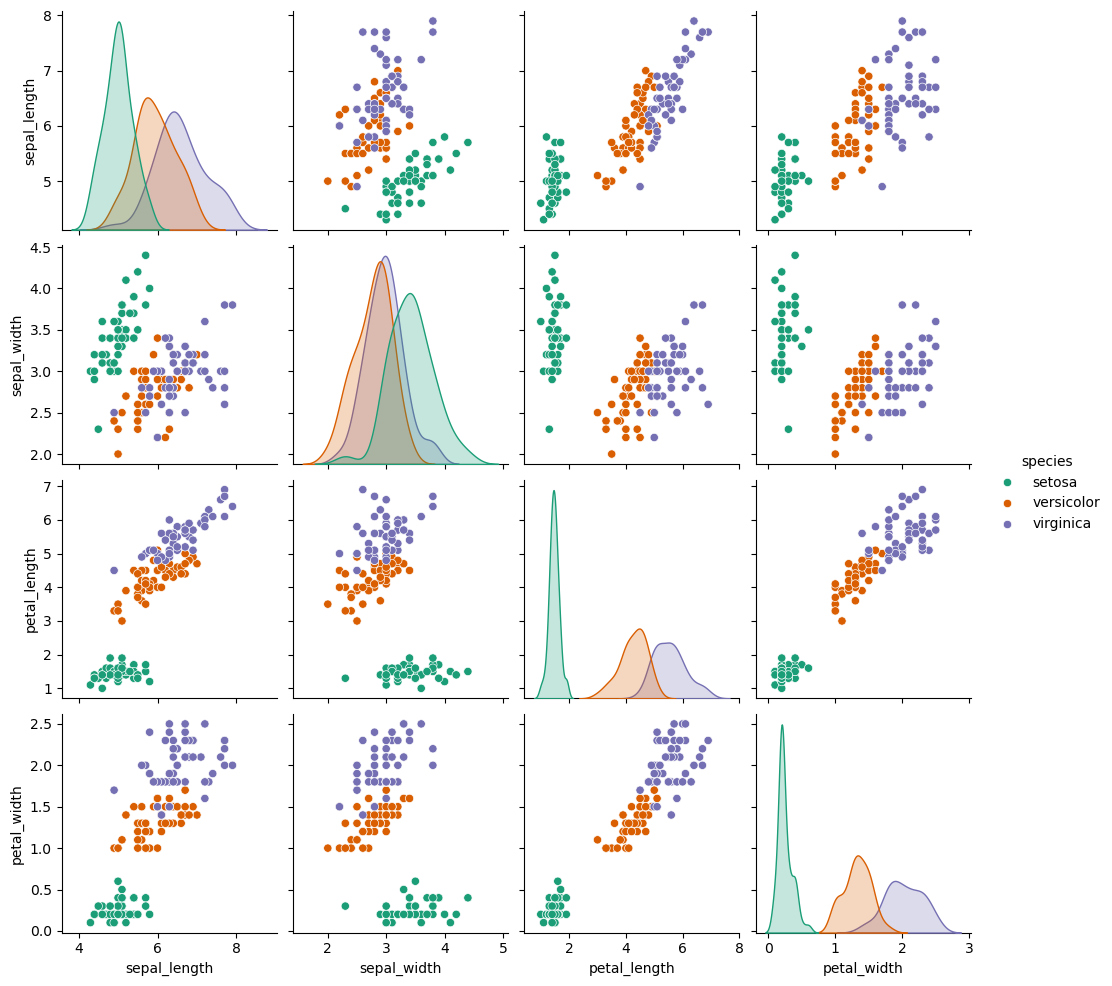

In [15]:
sns.pairplot(iris, hue='species',palette='Dark2')

## Train-test split
### Направете поделба на податочното множество
**помош: train_test_split(random_state=0)**

In [16]:
X = iris.drop('species',axis=1)
y = iris['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=0)

## Тренирање на модел
Истренирајте модел на SVM врз податочното множество за тренирање за следните параметри:
* **kernel:** "rbf"
* **gamma:** 1e-2
* **tol:** 1e-6
  
**помош: SVC()**

In [17]:
model = SVC(C=1,kernel='rbf', gamma=1e-2, tol=1e-6)

In [18]:
model.fit(X_train, y_train)

AttributeError: 'bool' object has no attribute 'all'

AttributeError: 'bool' object has no attribute 'all'

SVC(C=1, gamma=0.01, tol=1e-06)

## Евалуација на модел
### Евалуирајте го моделот за тест множеството со помош на метрика за средна точност (mean accuracy)
**SVC.*.score()**

In [ ]:
model.score(X_test, y_test)

## GrdSearchCV функција за нагодување на параметри
Многу често при нагодување на параметрите на еден модел потребно е да се тренира и евалуира моделот одново за различни комбинации на вредности на параметрите.

Пример:
Замислете доколку е потребно да се нагодат параметри на еден SVM модел и притоа сакаме да ги испробаме сите комбинации за вредностите {'C': [0.1, 1], 'gamma': [1, 0.1]}. Во тој случај ќе треба за секоја комбинација на вредности одново да тренираме нов модел и да извршиме евалуација. Во овој случај листата на комбинации е: [(0.1, 1), (0.1, 0.1), (1, 1), (1, 0.1)]. Според тоа ќе треба четири пати да тренираме нов модел и да евалуираме, а потоа да ја определиме најдобрата комбинација на вредности, за параметрите, врз основа на евалуација на секој од четирите модели.

Да се реализира оваа постапка рачно е многу истоштувачка работа. GridSearchCV класата овозможува да се автоматизира овој процес и при тоа автоматски да ја добиеме најдобрата комбинација на параметри.

## Грубо нагодување на C и gamma параметрите
GridSearchCV класата нуди исцрпно тренирање на онолку модели за колку што е потребно да се провераат сите торки на вредности за параметрите C и gamma. Сите модели се евалуираат со помош на K-fold вкрстена валидација, а потоа се избира најдобриот. Најпрво ќе направиме грубо нагодување така што ќе избереме мал број на вредности во определен опсег.

**домашна задача: информирајте се како функционира k-fold cross validation**
### Пример
Ќе автоматизираме процес на тренирање и евалуација на SVM модели за следните параметри на C и gamma:

* {'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 10]} 

Дефинираниот модел кој ќе се нагодува е сместен во променливата **model** и истиот ќе го тренираме и евалуираме за сите комбинации на параметри сместени во **params**. При евалуација на моделот ќе се користи 5-fold cross validation кое се избира со поставување на параметарот **cv=5** или **cv=None**. Метриката која ќе се користи за евалуација на моделот ќе биде default метрика која е имплементиравана во SVC.*.score() функцијата, па затоа **scoring=None**. Доколку сакате, можете да имплементирате ваша (custom) функција за евалуација на моделот која ќе ја дадете на влез на **scoring** параметарот. Поради тоа што gridsearch операцијата треба да тренира и евалуира повеќе модели независно еден од друг, можеме да примениме паралелизација на процесот така што секој модел ќе се проверува независно за секоја нитка од процесорот на компјутерот. Во овој случај се резервирани **n_jobs=11** нитки за процесот чиј број е избран за 6-јадрен процесор. Вообичаано се препорачува овој број да биде 2*n - 1 каде n е бројот на јадра во процесорот. Параметарот **verbose** се користи за да одбереме колкава количина на информации сакаме да добиваме во текот на операцијата gridsearch.

In [23]:
params = {'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 10]} 

In [24]:
grid = GridSearchCV(estimator=model, 
                    param_grid=params, 
                    scoring=None, 
                    refit=True,
                    n_jobs=11,
                    cv=None,
                    
                    verbose=2)
cv_results = grid.fit(X_train,y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


In [25]:
grid.best_params_

{'C': 10, 'gamma': 0.1}

In [ ]:
print('Accuracy of the model: ', grid.score(X_test, y_test))

Можеме да забележиме дека за новите параметри добиени од gridsearch операцијата добивме подобрување во точноста за 0.04%.

## Фино подесување на параметрите C и gamma
### Извршете фино нагодување на параметрите C и gamma така што ќе бидат испробани следните вредности:

* **C:** 100 еквидистантни вредности во опсег од [1e-3, 10]
* **gamma:** 100 еквидистантни вредности во опсег од [1e-3, 10]

In [27]:
param_grid = {'C': np.linspace(1e-3, 10, 100), 'gamma': np.linspace(1e-3,10,100)}
param_grid

{'C': array([1.000e-03, 1.020e-01, 2.030e-01, 3.040e-01, 4.050e-01, 5.060e-01,
        6.070e-01, 7.080e-01, 8.090e-01, 9.100e-01, 1.011e+00, 1.112e+00,
        1.213e+00, 1.314e+00, 1.415e+00, 1.516e+00, 1.617e+00, 1.718e+00,
        1.819e+00, 1.920e+00, 2.021e+00, 2.122e+00, 2.223e+00, 2.324e+00,
        2.425e+00, 2.526e+00, 2.627e+00, 2.728e+00, 2.829e+00, 2.930e+00,
        3.031e+00, 3.132e+00, 3.233e+00, 3.334e+00, 3.435e+00, 3.536e+00,
        3.637e+00, 3.738e+00, 3.839e+00, 3.940e+00, 4.041e+00, 4.142e+00,
        4.243e+00, 4.344e+00, 4.445e+00, 4.546e+00, 4.647e+00, 4.748e+00,
        4.849e+00, 4.950e+00, 5.051e+00, 5.152e+00, 5.253e+00, 5.354e+00,
        5.455e+00, 5.556e+00, 5.657e+00, 5.758e+00, 5.859e+00, 5.960e+00,
        6.061e+00, 6.162e+00, 6.263e+00, 6.364e+00, 6.465e+00, 6.566e+00,
        6.667e+00, 6.768e+00, 6.869e+00, 6.970e+00, 7.071e+00, 7.172e+00,
        7.273e+00, 7.374e+00, 7.475e+00, 7.576e+00, 7.677e+00, 7.778e+00,
        7.879e+00, 7.980e+00, 8.0

In [ ]:
grid = GridSearchCV(estimator=model, 
                    param_grid=param_grid, 
                    scoring=None, 
                    refit=True,
                    n_jobs=2,
                    cv=5,
                    verbose=11)
cv_results = grid.fit(X_train,y_train)

[CV] END ...................................C=0.1, gamma=0.1; total time=   0.0s
[CV] END ......................................C=1, gamma=10; total time=   0.0s
[CV] END ......................................C=1, gamma=10; total time=   0.0s
[CV] END ......................................C=1, gamma=10; total time=   0.0s
[CV] END ......................................C=1, gamma=10; total time=   0.0s
[CV] END ......................................C=10, gamma=1; total time=   0.0s
[CV] END ......................................C=10, gamma=1; total time=   0.0s
[CV] END ....................................C=10, gamma=0.1; total time=   0.0s
[CV] END ...................................C=10, gamma=0.01; total time=   0.0s
[CV] END .....................................C=10, gamma=10; total time=   0.0s
[CV] END .....................................C=100, gamma=1; total time=   0.0s
[CV] END ...................................C=100, gamma=0.1; total time=   0.0s
[CV] END ...................

In [ ]:
grid.best_params_

Може да се забележи дека не се доби никакво подобрување во споредба со грубото нагодување на параметрите, но сепак може да се забележи дека параметрите се сосема различни. Тоа резултат на тоа што јадрото е нелинеарно и поради тоа функцијата на цена нема еден минимум туку повеќе локални минимуми.

In [ ]:
print('Accuracy of the model: ', grid.score(X_test, y_test))